# 03 — K-Means Clustering of Celestial Objects
**Author:** Ritu Raj (`dev-ritu`)  
**Input:** `../data/processed/sdss_pca_2d.csv` (from Sakshi)  
**Output:** `../figures/kmeans_cluster_comparison.png`

**Question:** How closely do three groups formed from two photometric PCA coordinates correspond to the SDSS classes STAR, GALAXY and QSO (quasar)?

**Run in VS Code**
1. Save this notebook at `notebooks/03_kmeans_clustering.ipynb` in the team repository.
2. Select the Python kernel where you installed the team's `requirements.txt`.
3. Run all cells in practice mode. When Sakshi's `data/processed/sdss_pca_2d.csv` arrives, set `USE_PRACTICE_DATA = False`, restart the kernel, and run all cells again.
4. Check the plot and use the real printed scores to complete the interpretation at the bottom. Save the notebook on `dev-ritu`.

The expected CSV columns are `pc1`, `pc2`, and `class`, with the actual class attached to the same object as its coordinates. `PC1` and `PC_1` (and the corresponding PC2 spellings) are accepted too. Each row represents one object. PC1 and PC2 are combinations of the five standardized photometric bands. The model sees those two coordinates. The `class` column is used afterward to evaluate the clusters.

## 1. Load the coordinates

The small practice dataset is made up. It exercises the same code as the real CSV. Only a real-data run exports the figure for the project.

In [5]:
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

USE_PRACTICE_DATA = False

csv_path = Path("data/processed/sdss_pca_2d.csv")
if Path.cwd().name == "notebooks":
    csv_path = Path("..") / csv_path

class_names = ["STAR", "GALAXY", "QSO"]
class_colors = {"STAR": "gold", "GALAXY": "royalblue", "QSO": "crimson"}

if USE_PRACTICE_DATA:
    rng = np.random.default_rng(42)
    practice_centers = [(-2.0, 0.0), (1.2, 1.0), (2.1, -0.7)]
    coordinates = [
        rng.normal(loc=center, scale=0.85, size=(40, 2))
        for center in practice_centers
    ]
    data = pd.DataFrame(np.vstack(coordinates), columns=["pc1", "pc2"])
    data["class"] = np.repeat(class_names, 40)
    run_name = "Practice data"
else:
    if not csv_path.is_file():
        raise FileNotFoundError(
            f"Expected {csv_path.resolve()}. Open the team repository in VS Code "
            "and check that Sakshi's CSV is in data/processed/."
        )
    data = pd.read_csv(csv_path)
    data.columns = data.columns.str.strip().str.lower()
    data = data.rename(columns={"pc_1": "pc1", "pc_2": "pc2"})
    run_name = "SDSS PCA data"

required_columns = ["pc1", "pc2", "class"]
missing_columns = [column for column in required_columns if column not in data.columns]
if missing_columns:
    raise ValueError(
        f"Missing {missing_columns}. Found {list(data.columns)}. "
        "Check the CSV headers and ask Sakshi to export both PCs and the class together."
    )

data = data[required_columns].copy()
X = data[["pc1", "pc2"]].apply(pd.to_numeric, errors="raise")
if not np.isfinite(X.to_numpy()).all():
    raise ValueError("PC1 and PC2 must contain finite numbers for every object.")
if len(X.drop_duplicates()) < 3:
    raise ValueError("K-Means with k=3 needs at least three distinct points.")

data["class"] = data["class"].astype("string").str.strip().str.upper()
if data["class"].isna().any() or set(data["class"].dropna()) != set(class_names):
    raise ValueError("Expected labeled rows and all three classes: STAR, GALAXY and QSO.")

print(f"{run_name} | {len(data):,} objects")
data.head()

SDSS PCA data | 99,999 objects


,pc1,pc2,class
0,0.900412,0.762372,GALAXY
1,2.979399,-0.133584,GALAXY
2,1.368166,1.189625,GALAXY
3,1.720505,-0.069991,GALAXY
4,-3.581485,0.349470,GALAXY


## 2. Fit three clusters

1. Start with three center points (centroids).
2. Assign each object to its nearest centroid using Euclidean distance.
3. Move each centroid to the mean coordinates of its assigned objects. Repeat the assignment and update until convergence or the iteration limit.

### Work one step by hand

The point $(4,2)$ is between two example centers, $A=(1,2)$ and $B=(6,2)$. Its squared distances are $(4-1)^2+(2-2)^2=9$ and $(4-6)^2+(2-2)^2=4$. It joins $B$. If $B$ then contains $(4,2)$ and $(6,2)$, its new center is $(5,2)$. The real run does the same assignment and mean update with three centers and many rows.

K-Means tries to minimize the sum of squared distances from each object to its assigned centroid. We set $k=3$ to compare with the three known classes. The random seed helps reproduce the run, and `n_init=10` tries ten initializations and keeps the one with the smallest sum of squared distances.

In [6]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)
data["cluster"] = model.fit_predict(X)

print(f"Iterations for the best initialization: {model.n_iter_}")
pd.DataFrame(model.cluster_centers_, columns=["PC1", "PC2"]).rename_axis("Cluster")

Iterations for the best initialization: 22


,PC1,PC2
Cluster,,
0,-0.128571,0.069145
1,1.777801,-0.019930
2,-2.976988,-0.044209


## 3. Compare clusters with the true classes

Cluster IDs 0, 1 and 2 are arbitrary. The count table tells us how many objects from each true class landed in each cluster.

- **Purity:** Take the largest count from each cluster row, add those counts, and divide by the total number of objects. Two clusters can have the same majority class.
- **Best-matched accuracy:** Match each cluster to a different class. With three classes there are six possible assignments. Find the assignment that matches the most objects, then divide by the total. This is an agreement score on the data we clustered. It describes this dataset and does not measure test-set prediction.

For example, if the rows (in STAR, GALAXY, QSO order) are `[4,1,0]`, `[3,2,0]` and `[0,0,5]`, purity is $(4+3+5)/15=80\%$. The best unique match picks STAR, GALAXY and QSO for those rows, giving $(4+2+5)/15=73.3\%$.

In [7]:
clusters = [0, 1, 2]
counts = pd.crosstab(data["cluster"], data["class"]).reindex(
    index=clusters, columns=class_names, fill_value=0
)
purity = counts.max(axis=1).sum() / len(data)

best_score = -1
best_mapping = {}
for class_order in permutations(class_names):
    mapping = dict(zip(clusters, class_order))
    matches = sum(counts.loc[cluster, label] for cluster, label in mapping.items())
    if matches > best_score:
        best_score = matches
        best_mapping = mapping

matched_accuracy = best_score / len(data)
largest_class_share = counts.sum(axis=0).max() / len(data)

print(f"{run_name} | Purity: {purity:.2%}")
print(f"Best-matched accuracy: {matched_accuracy:.2%}")
print(f"Largest true class share: {largest_class_share:.2%}")
for cluster in clusters:
    print(f"Cluster {cluster} maps to {best_mapping[cluster]} in the best unique match.")
counts

SDSS PCA data | Purity: 59.45%
Best-matched accuracy: 42.14%
Largest true class share: 59.45%
Cluster 0 maps to QSO in the best unique match.
Cluster 1 maps to GALAXY in the best unique match.
Cluster 2 maps to STAR in the best unique match.


class,STAR,GALAXY,QSO
cluster,,,
0,6867,16055,6600
1,6195,27010,11596
2,8531,16380,765


## 4. Plot the same objects twice

The left panel colors each point by its SDSS class. The right panel colors those same points by the assigned K-Means cluster. The X symbols mark the learned centroids. Use the count table to check where a cluster mixes classes or splits a class across several clusters.

Saved ..\figures\kmeans_cluster_comparison.png


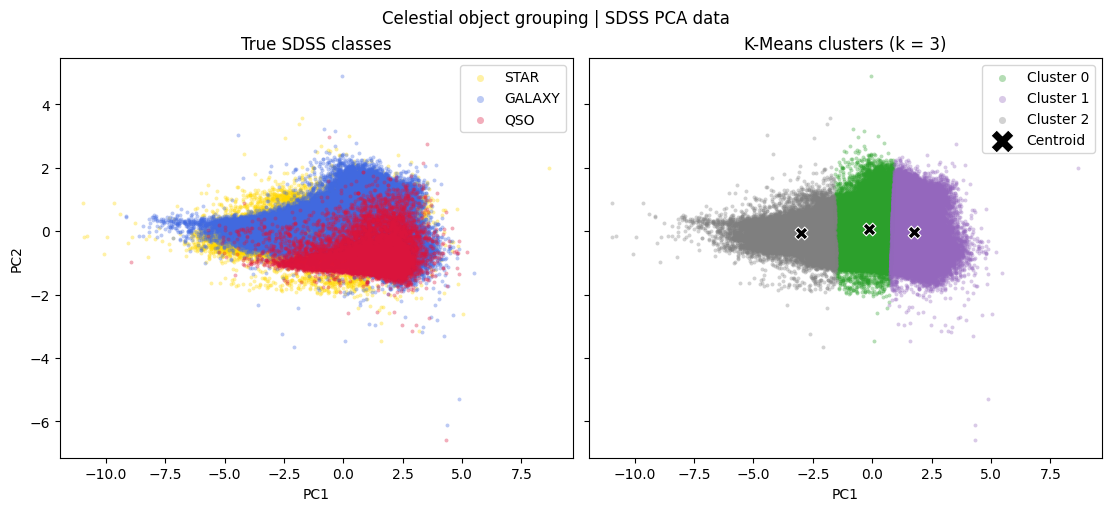

In [8]:
fig, (true_ax, cluster_ax) = plt.subplots(
    1, 2, figsize=(11, 5), sharex=True, sharey=True, constrained_layout=True
)

for label, color in class_colors.items():
    points = data.loc[data["class"] == label]
    true_ax.scatter(
        points["pc1"], points["pc2"], label=label,
        color=color, s=8, alpha=0.35, linewidths=0
    )
true_ax.set_title("True SDSS classes" if not USE_PRACTICE_DATA else "Practice labels")

cluster_colors = ["tab:green", "tab:purple", "tab:gray"]
for cluster, color in zip(clusters, cluster_colors):
    points = data.loc[data["cluster"] == cluster]
    cluster_ax.scatter(
        points["pc1"], points["pc2"], label=f"Cluster {cluster}",
        color=color, s=8, alpha=0.35, linewidths=0
    )

centers = model.cluster_centers_
cluster_ax.scatter(
    centers[:, 0], centers[:, 1], marker="X", s=85,
    color="black", edgecolors="white", linewidths=0.8, label="Centroid"
)
cluster_ax.set_title("K-Means clusters (k = 3)")

for ax in (true_ax, cluster_ax):
    ax.set_xlabel("PC1")
    ax.legend(loc="best", markerscale=1.8)
true_ax.set_ylabel("PC2")
fig.suptitle(f"Celestial object grouping | {run_name}")

if not USE_PRACTICE_DATA:
    figures_dir = csv_path.parents[2] / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    figure_path = figures_dir / "kmeans_cluster_comparison.png"
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    print(f"Saved {figure_path}")

plt.show()